# Profils des joueurs d’Auckland FC — Zone 14

Ce notebook identifie les trois joueurs d’Auckland FC les plus impliqués dans la zone 14 lors des quatre matchs étudiés. Il complète cette sélection par leurs statistiques saisonnières de passes, de courses sans ballon et d’activité physique.

Les traitements réutilisables sont définis dans `fonctions_zone14.py` et `fonctions_profils.py`. Ce notebook explique leur mise en œuvre et les choix méthodologiques. L’interprétation des résultats est réservée à `synthèse.ipynb`.

## 1. Importation des fonctions

Le dossier `src` est ajouté au chemin de recherche Python avec `sys.path` afin d’importer les fonctions écrites pour le projet. Celles de `fonctions_zone14.py` sélectionnent les actions dans la zone 14. Celles de `fonctions_profils.py` regroupent les actions par joueur, construisent les tableaux saisonniers et représentent les percentiles.

Cette séparation évite de répéter les mêmes traitements dans les notebooks 02 et 03.

In [68]:
import pandas as pd
import s3fs
import json
import sys
from pathlib import Path

#on indique le chemin du dossier src
if Path('src').exists():
    sys.path.append('src')
else:
    sys.path.append('../src')

from fonctions_zone14 import (
    passes_depuis_zone14,
    frappes_depuis_zone14,
    passes_vers_zone14,
    courses_vers_zone14,
    courses_depuis_zone14
)
from fonctions_profils import (
    compter_actions_joueurs, 
    tableau_percentiles,
    tableau_identite, 
    tableau_profils, 
    graphique_percentiles
)

## 2. Chargement et préparation des données

Nous reprenons les quatre matchs étudiés dans le notebook 02 et les trois bases saisonnières SkillCorner consacrées aux passes, aux courses sans ballon et à l’activité physique. Le chargement suit la même méthode que dans les notebooks précédents.

On récupère aussi les données de saison de la même façon que dans le premier notebook.

In [69]:
fs = s3fs.S3FileSystem(
    endpoint_url='https://minio.lab.sspcloud.fr',
    client_kwargs={'region_name': 'us-east-1'}
)

ids_matchs = [1886347, 1899585, 2015213, 2017461]
matchs = {}

for id_match in ids_matchs:
    evenements = pd.read_parquet(
        f's3://lfaivre/diffusion/{id_match}_dynamic_events.parquet',
        filesystem=fs
    )
    with fs.open(f's3://lfaivre/diffusion/{id_match}_match.json', 'r') as fichier:
        infos = json.load(fichier)
    nom_match = infos['home_team']['name'] + ' - ' + infos['away_team']['name']
    matchs[nom_match] = (infos, evenements)

id_auckland = 4177
print('Nombre de matchs chargés :', len(matchs))

Nombre de matchs chargés : 4


In [70]:
#on charge les bases de saison
obr = pd.read_parquet(
    's3://lfaivre/diffusion/aus1league_obraggregates_20242025.parquet',
    filesystem=fs
)
passing = pd.read_parquet(
    's3://lfaivre/diffusion/aus1league_passingaggregates_20242025.parquet',
    filesystem=fs
)
physical = pd.read_parquet(
    's3://lfaivre/diffusion/aus1league_physicalaggregates_20242025.parquet',
    filesystem=fs
)

MIN_MATCHES = 3
pas = passing.loc[passing['performance_count'] >= MIN_MATCHES].copy()
courses = obr.loc[obr['performance_count'] >= MIN_MATCHES].copy()
phys = physical.loc[physical['count_match'] >= MIN_MATCHES].copy()

for df in [pas, courses, phys]:
    df['equipe'] = df['team_name'].str.replace(' Football Club', '')
    df['equipe'] = df['equipe'].str.replace(' FC', '')
    df['player_id'] = df['player_id'].astype(int)

print('Joueurs dans les bases :', len(pas), len(courses), len(phys))

Joueurs dans les bases : 263 263 271


## 3. Sélection des actions liées à la zone 14

Les cinq fonctions de `fonctions_zone14.py` reprennent les critères définis et justifiés dans le notebook 02. Elles identifient les passes et les tirs depuis la zone 14, les passes estimées vers cette zone et les courses qui y entrent ou en sortent.

Chaque catégorie est calculée pour les quatre matchs. Les résultats sont conservés dans un dictionnaire par catégorie et par rencontre. Les passes vers la zone 14 restent des estimations construites à partir de possessions successives et non des réceptions certaines.

In [71]:
#on prépare les cinq dictionnaires, avec un DataFrame par match
resultats_passes_depuis = {}
resultats_frappes_depuis = {}
resultats_passes_vers = {}
resultats_courses_vers = {}
resultats_courses_depuis = {}

for nom, (infos, evenements) in matchs.items():
    resultats_passes_depuis[nom] = passes_depuis_zone14(infos, evenements, id_auckland)
    resultats_frappes_depuis[nom] = frappes_depuis_zone14(infos, evenements, id_auckland)
    resultats_passes_vers[nom] = passes_vers_zone14(infos, evenements, id_auckland)
    resultats_courses_vers[nom] = courses_vers_zone14(infos, evenements, id_auckland)
    resultats_courses_depuis[nom] = courses_depuis_zone14(infos, evenements, id_auckland)

actions_zone14 = {
    'passes_depuis': resultats_passes_depuis,
    'frappes_depuis': resultats_frappes_depuis,
    'passes_vers': resultats_passes_vers,
    'courses_vers': resultats_courses_vers,
    'courses_depuis': resultats_courses_depuis
}



## 4. Classement des joueurs par implication dans la zone 14

La fonction `compter_actions_joueurs()` de `fonctions_profils.py` réunit les tableaux de chaque catégorie avec `pd.concat()`, compte les événements par `player_id` avec `groupby()` et rapproche les catégories avec `merge()`.

Le regroupement externe `how='outer'` conserve les joueurs présents dans une seule catégorie. Les cases vides des nombres d’actions sont remplacées par zéro avec `fillna(0)`, puis `sum(axis=1)` fournit le total par joueur. Les noms sont recherchés dans les données de saison et, lorsqu’ils n’y figurent pas, dans les événements des matchs.

Nous retenons les trois premiers joueurs avec `head(3)`. Le classement additionne cinq types d’actions, qui n’ont pas nécessairement la même importance tactique. Il mesure le volume d’implication sur quatre matchs, pas l’efficacité individuelle.

In [72]:
#on compte les actions puis on ajoute les noms des joueurs
usage_joueurs = compter_actions_joueurs(actions_zone14)

noms_saison = []
for identifiant in usage_joueurs['player_id']:
    lignes = pas.loc[pas['player_id'] == identifiant]
    if len(lignes) > 0:
        noms_saison.append(lignes['player_name'].iloc[0])
    else:
        #si le joueur n'est pas dans la base de passes, on cherche dans les événements
        nom_trouve = 'Absent des données de saison'
        for nom_match, (infos, evenements) in matchs.items():
            noms = evenements.loc[
                evenements['player_id'].astype(float) == identifiant,
                'player_name'
            ].dropna()
            if len(noms) > 0:
                nom_trouve = noms.iloc[0]
                break
        noms_saison.append(nom_trouve)

usage_joueurs['nom_joueur'] = noms_saison

colonnes_usage = [
    'nom_joueur', 'player_id', 'passes_depuis', 'frappes_depuis',
    'passes_vers', 'courses_vers', 'courses_depuis', 'total'
]
print('Les dix joueurs les plus impliqués')
noms_colonnes_usage = {
    'nom_joueur': 'Joueur',
    'player_id': 'Identifiant',
    'passes_depuis': 'Passes depuis Z14',
    'frappes_depuis': 'Tirs depuis Z14',
    'passes_vers': 'Passes vers Z14 estimées',
    'courses_vers': 'Courses vers Z14',
    'courses_depuis': 'Courses depuis Z14',
    'total': 'Total des actions'
}
usage_joueurs[colonnes_usage].head(10).rename(columns=noms_colonnes_usage).round(0)

Les dix joueurs les plus impliqués


,Joueur,Identifiant,Passes depuis Z14,Tirs depuis Z14,Passes vers Z14 estimées,Courses vers Z14,Courses depuis Z14,Total des actions
4,Guillermo Luis May Bartesaghi,38673,4,3,3,17,24,51
11,Logan Rogerson,133501,4,1,1,9,13,28
16,Liam Gillion,965685,4,1,5,3,13,26
6,Jake Brimmer,50951,2,1,6,3,9,21
2,Luis Felipe Gallegos Leiva,23418,5,2,3,2,9,21
1,Louis Verstraete,14736,7,3,2,4,2,18
5,Neyder Stiven Moreno Betancur,43829,1,2,2,5,6,16
12,Max Mata,163972,0,0,0,5,8,13
13,Marlee Francois,582974,1,0,1,2,4,8
10,Francis De Vries,133498,2,1,3,1,1,8


In [73]:
#on conserve les 3 premiers joueurs
#leurs statistiques saisonnières seront analysées ci-dessous
top_joueurs = usage_joueurs.head(3).copy()

print('Les 3 joueurs retenus :')
top_joueurs[['nom_joueur', 'player_id', 'total']].round(0)

Les 3 joueurs retenus :


,nom_joueur,player_id,total
4,Guillermo Luis May Bartesaghi,38673,51
11,Logan Rogerson,133501,28
16,Liam Gillion,965685,26


## 5. Profil saisonnier des trois joueurs

Avant le calcul des percentiles, les tableaux présentent la valeur saisonnière de chaque indicateur pour les trois joueurs retenus, ainsi que les moyennes d’Auckland et de la ligue.

Dans `fonctions_profils.py`, `tableau_identite()` rassemble les informations de poste, de matchs, de minutes et d’implication en zone 14. Pour une observation présente à plusieurs postes, la ligne comptant le plus de matchs est retenue comme poste principal. `ligne_principale()` et `valeur_joueur()` appliquent la même convention à la récupération des statistiques individuelles.

La fonction `tableau_profils()` parcourt les indicateurs regroupés dans `bases_saison` et construit une colonne par joueur, puis deux colonnes de moyennes. Les statistiques sont conservées dans leurs unités SkillCorner. Les mesures par 30 minutes de possession ne doivent pas être confondues avec les mesures par match.

In [74]:
#chaque famille d'indicateurs vient d'une base de saison : on indique la base et la colonne du nombre de matchs
bases_saison = {
    'Passes': (pas, 'performance_count'),
    'Courses sans ballon': (courses, 'performance_count'),
    'Physique': (phys, 'count_match')
}

#chaque indicateur est un tuple : (famille, variable SkillCorner, nom affiché)
indicateurs_passes = [
    ('Passes', 'pass_count_attempted_p30tip', 'Passes tentées (par 30 min de possession)'),
    ('Passes', 'pass_count_completed_p30tip', 'Passes réussies (par 30 min de possession)'),
    ('Passes', 'pass_pct_completed', 'Taux de passes réussies (%)'),
    ('Passes', 'pass_count_difficultpass_attempted_p30tip', 'Passes difficiles tentées (par 30 min)'),
    ('Passes', 'pass_count_longrange_attempted_p30tip', 'Passes longues tentées (par 30 min)'),
    ('Passes', 'pass_count_linebreak_attempted_p30tip', 'Passes cassant une ligne tentées (par 30 min)'),
    ('Passes', 'pass_count_linebreak_completed_p30tip', 'Passes cassant une ligne réussies (par 30 min)'),
    ('Passes', 'pass_count_dangerous_attempted_p30tip', 'Passes dangereuses tentées (par 30 min)'),
    ('Passes', 'pass_count_dangerous_completed_p30tip', 'Passes dangereuses réussies (par 30 min)'),
    ('Passes', 'pass_count_shotwithin10s_p30tip', 'Passes suivies d’un tir sous 10 s (par 30 min)'),
]

indicateurs_courses = [
    ('Courses sans ballon', 'offballrun_count_p30tip', 'Courses sans ballon (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_targeted_p30tip', 'Courses visées par une passe (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_received_p30tip', 'Courses avec réception (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_dangerous_p30tip', 'Courses dangereuses (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_penaltyarea_p30tip', 'Courses dans la surface (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_shotwithin10s_p30tip', 'Courses suivies d’un tir sous 10 s (par 30 min)'),
    ('Courses sans ballon', 'offballrun_count_abovehsr_p30tip', 'Courses à haute vitesse (par 30 min)'),
    ('Courses sans ballon', 'offballrun_avgdistance', 'Distance moyenne des courses (m)')
]


indicateurs_physiques = [
    ('Physique', 'total_distance_full_all', 'Distance totale par match (m)'),
    ('Physique', 'total_metersperminute_full_all', 'Mètres par minute (temps total)'),
    ('Physique', 'hsr_distance_full_all', 'Distance à haute vitesse par match (m)'),
    ('Physique', 'sprint_count_full_all', 'Nombre de sprints par match'),
    ('Physique', 'sprint_distance_full_all', 'Distance en sprint par match (m)'),
    ('Physique', 'highaccel_count_full_all', 'Accélérations fortes par match'),
    ('Physique', 'psv99', 'Vitesse de pointe, psv99 (km/h)')
]

#dictionnaire variable -> utilisé plus loin pour les graphiques
var_indicateurs = {}
for famille, variable, nvar in indicateurs_passes + indicateurs_courses + indicateurs_physiques:
    var_indicateurs[variable] = nvar

### 5.1. Informations générales et temps de jeu

In [75]:
#poste(s), âge, matchs et minutes de la saison, puis usage de la zone 14 sur les quatre matchs
tableau_identite(top_joueurs, pas, courses, phys)

,Joueur,Poste principal,Postes joués (matchs),Âge (ans),Matchs retenus (60 min ou plus),Minutes par match,Actions en zone 14 (4 matchs)
0,Guillermo Luis May Bartesaghi,Center Forward,Center Forward (28),27.2,28,94.6,51
1,Logan Rogerson,Wide Attacker,Wide Attacker (22),27.1,22,81.7,28
2,Liam Gillion,Wide Attacker,Wide Attacker (11),22.7,11,86.8,26


### 5.2. Passes sur la saison

In [76]:
tableau_profils(top_joueurs, bases_saison, indicateurs_passes).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Moyenne Auckland,Moyenne ligue
0,Passes,Passes tentées (par 30 min de possession),36.49,28.00,39.25,39.60,41.38
1,Passes,Passes réussies (par 30 min de possession),29.58,21.08,29.10,31.72,34.77
2,Passes,Taux de passes réussies (%),81.04,75.29,74.16,78.89,82.32
3,Passes,Passes difficiles tentées (par 30 min),6.57,7.45,11.47,8.50,6.73
4,Passes,Passes longues tentées (par 30 min),1.90,0.53,0.00,1.98,2.40
5,Passes,Passes cassant une ligne tentées (par 30 min),2.68,1.17,2.65,5.42,6.28
6,Passes,Passes cassant une ligne réussies (par 30 min),1.64,0.96,2.20,3.91,4.61
7,Passes,Passes dangereuses tentées (par 30 min),6.49,5.64,10.14,4.43,3.82
8,Passes,Passes dangereuses réussies (par 30 min),4.06,2.66,5.29,2.16,2.13
9,Passes,Passes suivies d’un tir sous 10 s (par 30 min),2.77,2.55,3.53,1.96,2.01


### 5.3. Courses sans ballon sur la saison

In [77]:
tableau_profils(top_joueurs, bases_saison, indicateurs_courses).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Moyenne Auckland,Moyenne ligue
0,Courses sans ballon,Courses sans ballon (par 30 min),49.90,35.77,52.48,26.28,24.46
1,Courses sans ballon,Courses visées par une passe (par 30 min),18.77,12.56,16.32,9.14,8.47
2,Courses sans ballon,Courses avec réception (par 30 min),12.02,9.47,11.47,7.02,6.65
3,Courses sans ballon,Courses dangereuses (par 30 min),24.47,12.03,20.73,7.70,7.41
4,Courses sans ballon,Courses dans la surface (par 30 min),12.28,5.32,7.94,3.71,3.31
5,Courses sans ballon,Courses suivies d’un tir sous 10 s (par 30 min),1.99,0.85,3.09,0.88,0.84
6,Courses sans ballon,Courses à haute vitesse (par 30 min),13.40,10.22,18.96,6.70,5.71
7,Courses sans ballon,Distance moyenne des courses (m),13.53,14.05,14.53,12.86,12.56


### 5.4. Activité physique sur la saison

In [78]:
tableau_profils(top_joueurs, bases_saison, indicateurs_physiques).round(2)

,Catégorie,Indicateur,Guillermo Luis May Bartesaghi,Logan Rogerson,Liam Gillion,Moyenne Auckland,Moyenne ligue
0,Physique,Distance totale par match (m),10463.75,10223.09,10924.18,9762.07,10155.19
1,Physique,Mètres par minute (temps total),110.58,125.14,125.91,113.63,115.43
2,Physique,Distance à haute vitesse par match (m),746.68,798.36,761.45,587.84,539.92
3,Physique,Nombre de sprints par match,11.36,13.82,14.55,9.51,8.61
4,Physique,Distance en sprint par match (m),184.75,245.73,276.18,166.50,152.52
5,Physique,Accélérations fortes par match,10.68,6.23,7.55,5.91,5.44
6,Physique,"Vitesse de pointe, psv99 (km/h)",27.80,28.92,29.92,28.54,28.25


## 6. Sélection des indicateurs pour les comparaisons

Les listes `variables_passes_saison`, `variables_courses_saison` et `variables_physiques_saison` rassemblent les indicateurs retenus dans chacune des trois bases. Leur définition et leurs unités proviennent de SkillCorner.

La liste `variables_danger` repère certains indicateurs associés à la création d’occasions. Elle sert à les identifier dans les tableaux produits par `tableau_percentiles()` sans modifier leurs valeurs. Le dictionnaire `var_indicateurs` contient les noms français utilisés dans les graphiques. Le dictionnaire `noms_variables` reprend ces intitulés pour rendre les tableaux des parties 6 et 7 plus lisibles.

In [79]:
variables_passes_saison = [
    'pass_count_attempted_p30tip',
    'pass_pct_completed',
    'pass_count_linebreak_attempted_p30tip',
    'pass_count_dangerous_attempted_p30tip',
    'pass_count_dangerous_completed_p30tip',
    'pass_count_shotwithin10s_p30tip'
]

variables_courses_saison = [
    'offballrun_count_p30tip',
    'offballrun_count_targeted_p30tip',
    'offballrun_count_received_p30tip',
    'offballrun_count_dangerous_p30tip',
    'offballrun_count_penaltyarea_p30tip',
    'offballrun_count_shotwithin10s_p30tip'
]

variables_physiques_saison = [
    'psv99', 'sprint_count_full_all', 'hsr_distance_full_all'
]

variables_danger = [
    'pass_count_linebreak_attempted_p30tip',
    'pass_count_dangerous_attempted_p30tip',
    'pass_count_dangerous_completed_p30tip',
    'pass_count_shotwithin10s_p30tip',
    'offballrun_count_dangerous_p30tip',
    'offballrun_count_penaltyarea_p30tip',
    'offballrun_count_shotwithin10s_p30tip'
]

#on utilise des noms français pour afficher les indicateurs sélectionnés
noms_variables = var_indicateurs.copy()
lignes_noms_variables = []
for variable in variables_passes_saison + variables_courses_saison + variables_physiques_saison:
    lignes_noms_variables.append({
        'Nom de variable SkillCorner': variable,
        'Nom affiché': noms_variables[variable]
    })

pd.DataFrame(lignes_noms_variables)


,Nom de variable SkillCorner,Nom affiché
0,pass_count_attempted_p30tip,Passes tentées (par 30 min de possession)
1,pass_pct_completed,Taux de passes réussies (%)
2,pass_count_linebreak_attempted_p30tip,Passes cassant une ligne tentées (par 30 min)
3,pass_count_dangerous_attempted_p30tip,Passes dangereuses tentées (par 30 min)
4,pass_count_dangerous_completed_p30tip,Passes dangereuses réussies (par 30 min)
5,pass_count_shotwithin10s_p30tip,Passes suivies d’un tir sous 10 s (par 30 min)
6,offballrun_count_p30tip,Courses sans ballon (par 30 min)
7,offballrun_count_targeted_p30tip,Courses visées par une passe (par 30 min)
8,offballrun_count_received_p30tip,Courses avec réception (par 30 min)
9,offballrun_count_dangerous_p30tip,Courses dangereuses (par 30 min)


## 7. Calcul des percentiles

La fonction `tableau_percentiles()` récupère le profil saisonnier du joueur, puis calcule ses valeurs et ses rangs relatifs au sein de trois groupes. Ces groupes sont les joueurs d’Auckland, les joueurs du même groupe de postes dans la ligue et l’ensemble de la ligue.

La fonction `percentile()` commence par exclure les valeurs manquantes. Elle compte les observations inférieures à la valeur du joueur et attribue un demi-poids aux égalités. Un percentile de 80 signifie que la valeur se situe au-dessus d’environ 80 % de la distribution selon cette convention, en tenant compte des égalités. Il ne constitue pas une note de performance.

Lorsqu’un joueur possède plusieurs lignes de saison correspondant à différents postes, les groupes de référence peuvent inclure plusieurs observations du même joueur. Cette limite doit être gardée à l’esprit.

In [80]:
#on calcule les percentiles dans les trois bases de saison
lignes_percentiles = []

for identifiant in top_joueurs['player_id']:
    lignes_percentiles += tableau_percentiles(
        pas, identifiant, variables_passes_saison,
        'Passes', 'performance_count', variables_danger
    )
    lignes_percentiles += tableau_percentiles(
        courses, identifiant, variables_courses_saison,
        'Courses sans ballon', 'performance_count', variables_danger
    )
    lignes_percentiles += tableau_percentiles(
        phys, identifiant, variables_physiques_saison,
        'Physique', 'count_match', variables_danger
    )

percentiles_joueurs = pd.DataFrame(lignes_percentiles)
print('Nombre de lignes de profils :', len(percentiles_joueurs))

Nombre de lignes de profils : 45


In [81]:
#on affiche un tableau par joueur, avec des noms de colonnes français
noms_colonnes = {
    'categorie': 'Catégorie',
    'variable': 'Indicateur SkillCorner',
    'valeur': 'Valeur saison',
    'moyenne_coequipiers': 'Moyenne Auckland',
    'percentile_coequipiers': 'Percentile Auckland',
    'moyenne_ligue_meme_poste': 'Moyenne ligue même poste',
    'percentile_ligue_meme_poste': 'Percentile même poste',
    'percentile_ligue_tous_postes': 'Percentile ligue'
}

In [82]:
#joueur n°1 : son tableau de percentiles
joueur = top_joueurs.iloc[0]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau = tableau.copy()
tableau['variable'] = tableau['variable'].replace(noms_variables)
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Guillermo Luis May Bartesaghi


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
0,Passes,Passes tentées (par 30 min de possession),36.49,39.60,34.38,21.50,89.02,37.83
1,Passes,Taux de passes réussies (%),81.04,78.89,46.88,76.93,71.95,38.21
2,Passes,Passes cassant une ligne tentées (par 30 min),2.68,5.42,34.38,1.33,86.59,29.09
3,Passes,Passes dangereuses tentées (par 30 min),6.49,4.43,71.88,4.83,79.27,81.56
4,Passes,Passes dangereuses réussies (par 30 min),4.06,2.16,90.62,3.02,76.83,84.98
5,Passes,Passes suivies d’un tir sous 10 s (par 30 min),2.77,1.96,71.88,2.33,64.63,74.71
6,Courses sans ballon,Courses sans ballon (par 30 min),49.90,26.28,90.62,35.49,98.78,98.29
7,Courses sans ballon,Courses visées par une passe (par 30 min),18.77,9.14,96.88,11.98,96.34,98.67
8,Courses sans ballon,Courses avec réception (par 30 min),12.02,7.02,90.62,7.19,93.90,94.49
9,Courses sans ballon,Courses dangereuses (par 30 min),24.47,7.70,96.88,19.79,79.27,96.39


In [83]:
#joueur n°2 : son tableau de percentiles
joueur = top_joueurs.iloc[1]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau = tableau.copy()
tableau['variable'] = tableau['variable'].replace(noms_variables)
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Logan Rogerson


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
15,Passes,Passes tentées (par 30 min de possession),28.00,39.60,21.88,32.27,27.00,22.24
16,Passes,Taux de passes réussies (%),75.29,78.89,34.38,78.64,27.00,16.16
17,Passes,Passes cassant une ligne tentées (par 30 min),1.17,5.42,15.62,2.17,25.00,15.02
18,Passes,Passes dangereuses tentées (par 30 min),5.64,4.43,59.38,7.16,27.00,73.19
19,Passes,Passes dangereuses réussies (par 30 min),2.66,2.16,59.38,4.03,17.00,62.55
20,Passes,Passes suivies d’un tir sous 10 s (par 30 min),2.55,1.96,53.12,2.96,47.00,66.92
21,Courses sans ballon,Courses sans ballon (par 30 min),35.77,26.28,65.62,37.61,45.00,77.76
22,Courses sans ballon,Courses visées par une passe (par 30 min),12.56,9.14,71.88,13.43,41.00,79.66
23,Courses sans ballon,Courses avec réception (par 30 min),9.47,7.02,65.62,10.08,43.00,77.76
24,Courses sans ballon,Courses dangereuses (par 30 min),12.03,7.70,71.88,13.41,39.00,72.43


In [84]:
#joueur n°3 : son tableau de percentiles
joueur = top_joueurs.iloc[2]
print('PROFIL SAISONNIER :', joueur['nom_joueur'])
tableau = percentiles_joueurs.loc[
    percentiles_joueurs['player_id'] == joueur['player_id']
]
tableau = tableau.copy()
tableau['variable'] = tableau['variable'].replace(noms_variables)
tableau[list(noms_colonnes)].rename(columns=noms_colonnes).round(2)

PROFIL SAISONNIER : Liam  Gillion


,Catégorie,Indicateur SkillCorner,Valeur saison,Moyenne Auckland,Percentile Auckland,Moyenne ligue même poste,Percentile même poste,Percentile ligue
30,Passes,Passes tentées (par 30 min de possession),39.25,39.60,46.88,32.27,89.00,43.92
31,Passes,Taux de passes réussies (%),74.16,78.89,28.12,78.64,19.00,13.50
32,Passes,Passes cassant une ligne tentées (par 30 min),2.65,5.42,28.12,2.17,73.00,28.33
33,Passes,Passes dangereuses tentées (par 30 min),10.14,4.43,96.88,7.16,89.00,97.15
34,Passes,Passes dangereuses réussies (par 30 min),5.29,2.16,96.88,4.03,81.00,94.87
35,Passes,Passes suivies d’un tir sous 10 s (par 30 min),3.53,1.96,90.62,2.96,62.00,86.69
36,Courses sans ballon,Courses sans ballon (par 30 min),52.48,26.28,96.88,37.61,95.00,99.05
37,Courses sans ballon,Courses visées par une passe (par 30 min),16.32,9.14,90.62,13.43,89.00,96.39
38,Courses sans ballon,Courses avec réception (par 30 min),11.47,7.02,84.38,10.08,77.00,91.83
39,Courses sans ballon,Courses dangereuses (par 30 min),20.73,7.70,84.38,13.41,95.00,91.06


### 7.1. Représentation graphique des percentiles

La fonction `graphique_percentiles()` de `fonctions_profils.py` filtre les indicateurs disponibles pour un joueur avec `.loc[]` et `dropna()`. Pour chaque indicateur, `plt.plot()` trace un segment depuis zéro et `plt.scatter()` place un point au percentile observé. Les couleurs distinguent les passes, les courses sans ballon et le physique.

Les noms affichés proviennent du dictionnaire `var_indicateurs`. Le repère vertical situé à 50 facilite la lecture des valeurs médianes. Les graphiques portent sur les joueurs du même groupe de postes dans la ligue, ce qui limite les comparaisons entre rôles différents.

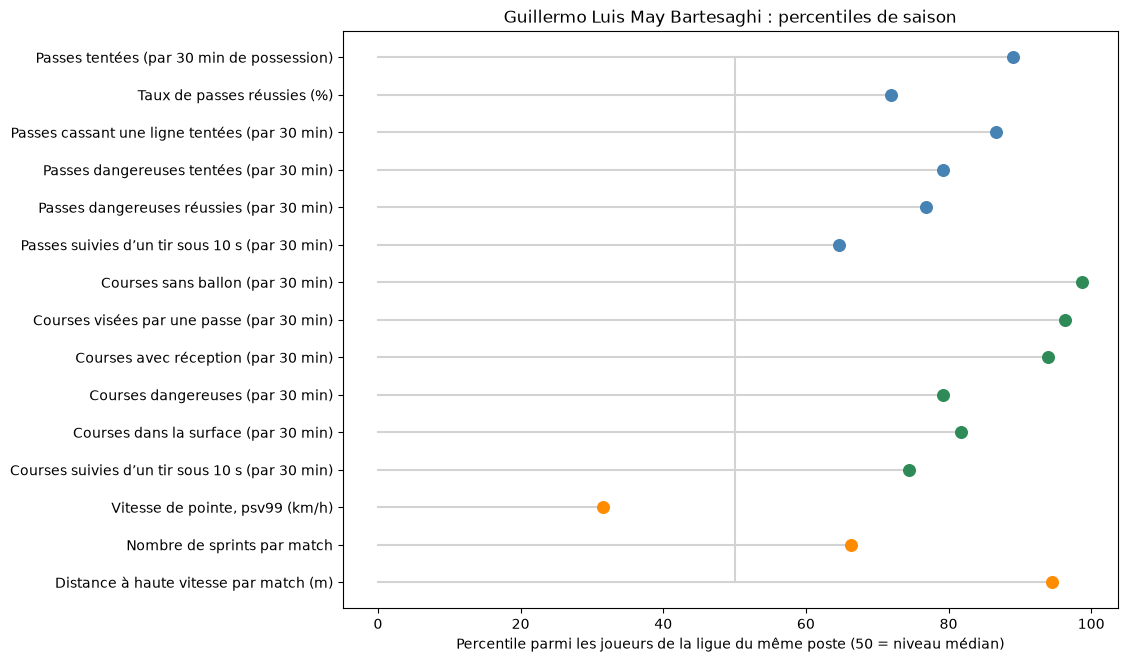

In [85]:
joueur = top_joueurs.iloc[0]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', var_indicateurs)

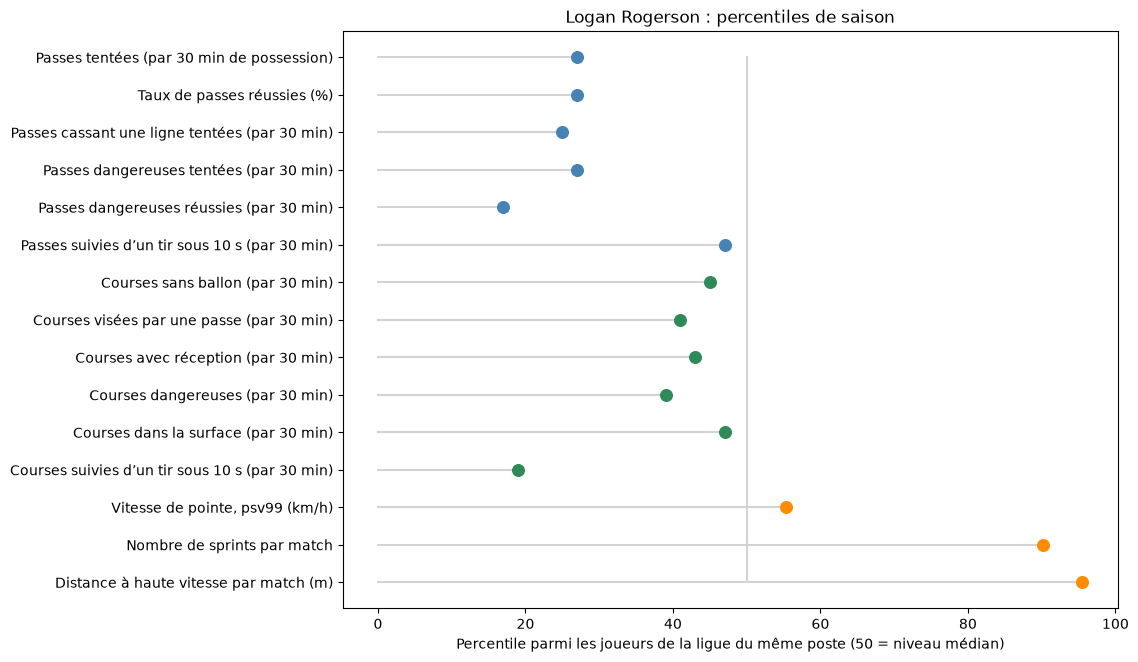

In [86]:
joueur = top_joueurs.iloc[1]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', var_indicateurs)

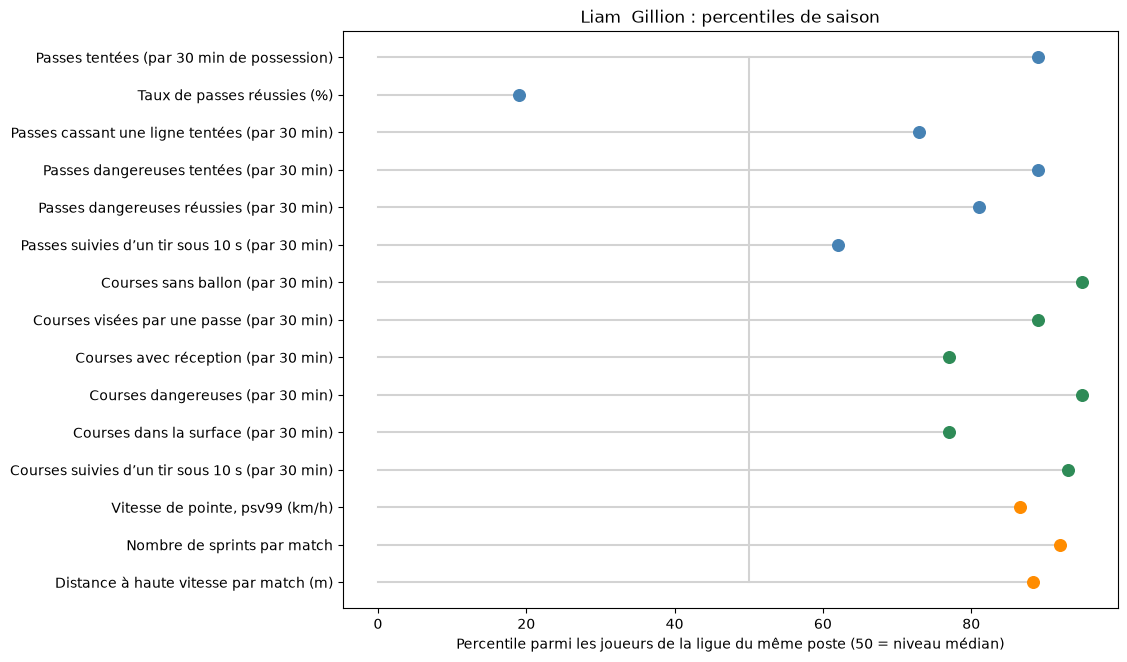

In [87]:
joueur = top_joueurs.iloc[2]
graphique_percentiles(percentiles_joueurs, joueur['player_id'],
                      joueur['nom_joueur'] + ' : percentiles de saison', var_indicateurs)